# Train RF-DETR (Local)

Local RF-DETR counterpart to the YOLO / RT-DETR notebooks.

Fine-tunes an RF-DETR detector (`RFDETRMedium`, COCO-pretrained) on the African wildlife dataset.

- **Dataset:** `data/wildlife_dataset` (images/labels with train/val/test splits)
- **Final trained model:** `ai-applications/trained_models`

## Dataset format

```text
wildlife_dataset/
├── wildlife_dataset.yaml
├── images/train
├── images/val
├── images/test
├── labels/train
├── labels/val
└── labels/test
```

RF-DETR reads the split paths from `wildlife_dataset.yaml` and finds each split's labels by swapping `images` for `labels` in the path.

Each label file uses:

```text
class_id center_x center_y width height
```

All coordinates must be normalized from 0 to 1.

In [93]:
%pip install -q rfdetr supervision pyyaml

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [94]:
import os

# Deterministic cuBLAS kernels; must be set before CUDA initializes (restart the kernel after changing)
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import cv2
import time
import shutil
import yaml
import torch
import numpy as np
import pandas as pd
import supervision as sv
from pathlib import Path
from supervision.metrics import MeanAveragePrecision, Precision, Recall, AveragingMethod
from rfdetr import RFDETRMedium, from_checkpoint
from rfdetr.utilities import seed_all
import rfdetr.datasets.yolo as rfdetr_yolo

print('CUDA available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

CUDA available: True
GPU: NVIDIA GeForce RTX 3070


In [ ]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]  # ai-applications/vs_notebooks -> repo root

DATASET_DIR = PROJECT_ROOT / 'data' / 'wildlife_dataset'
TRAINED_MODEL_DIR = PROJECT_ROOT / 'ai-applications' / 'trained_models'
RESULTS_DIR = PROJECT_ROOT / 'ai-applications' / 'training_results' / 'rf-detr'
RUNS_DIR = PROJECT_ROOT / 'ai-applications' / 'rfdetr_runs'
RUN_NAME = 'wildlife_rfdetr_medium'
OUTPUT_DIR = RUNS_DIR / RUN_NAME

MODEL_NAME = 'RF-DETR-M'
CLASS_NAMES = ['buffalo', 'elephant', 'lion', 'zebra']
SEED = 14  # fixed so re-running gives the same weights and metrics

assert DATASET_DIR.exists(), f'Dataset not found: {DATASET_DIR}'
TRAINED_MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Dataset:', DATASET_DIR)
print('Run output dir:', OUTPUT_DIR)
print('Results dir:', RESULTS_DIR)
print('Trained model dir:', TRAINED_MODEL_DIR)

Dataset: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset
Run output dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\rfdetr_runs\wildlife_rfdetr_medium
Results dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\training_results\rf-detr
Trained model dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\trained_models


In [96]:
DATA = DATASET_DIR / 'wildlife_dataset.yaml'

# Point the dataset YAML at this machine's dataset folder
with open(DATA, 'r') as f:
    dataset_config = yaml.safe_load(f)

dataset_config['path'] = str(DATASET_DIR)

with open(DATA, 'w') as f:
    yaml.safe_dump(dataset_config, f, sort_keys=False)

# RF-DETR only looks for data.yaml / data.yml in the dataset root; let it find wildlife_dataset.yaml too
if DATA.name not in rfdetr_yolo.REQUIRED_YOLO_YAML_FILES:
    rfdetr_yolo.REQUIRED_YOLO_YAML_FILES.insert(0, DATA.name)

print('Dataset YAML:', DATA)
print(dataset_config)

Dataset YAML: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset\wildlife_dataset.yaml
{'path': 'C:\\Users\\zheng\\Documents\\ISY5002-PRS-G14\\data\\wildlife_dataset', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'buffalo', 1: 'elephant', 2: 'lion', 3: 'zebra'}}


In [97]:
train_dir = DATASET_DIR / 'images' / 'train'
val_dir = DATASET_DIR / 'images' / 'val'
test_dir = DATASET_DIR / 'images' / 'test'

print('Dataset root:', DATASET_DIR)
print('Training images:', len([p for p in train_dir.iterdir() if p.is_file()]))
print('Validation images:', len([p for p in val_dir.iterdir() if p.is_file()]))
print('Test images:', len([p for p in test_dir.iterdir() if p.is_file()]))
print('Classes:', CLASS_NAMES)

Dataset root: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset
Training images: 1052
Validation images: 225
Test images: 227
Classes: ['buffalo', 'elephant', 'lion', 'zebra']


In [98]:
# num_classes must be set explicitly: RF-DETR can't auto-detect it from the images/<split> layout
# Seed before building the model: the new 4-class detection head is randomly initialized
seed_all(SEED)
model = RFDETRMedium(num_classes=len(CLASS_NAMES))
print('Model initialized: RFDETRMedium (COCO-pretrained weights)')

[2026-10-12 01:00:04] [INFO] rf-detr - File C:\Users\zheng\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


[2026-10-12 01:00:04] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 01:00:04] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-12 01:00:04] [INFO] rf-detr - File C:\Users\zheng\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


[2026-10-12 01:00:05] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 4. The detection head will be re-initialized to 4 classes.


Model initialized: RFDETRMedium (COCO-pretrained weights)


In [100]:
start_time = time.time()

model.train(
    dataset_dir=str(DATASET_DIR),
    dataset_file='yolo',
    class_names=CLASS_NAMES,
    epochs=50,
    batch_size=4,
    grad_accum_steps=4,  # effective batch size 16
    lr=1e-4,
    num_workers=2,
    early_stopping=True,
    early_stopping_patience=10,
    compute_val_loss=True,  # off by default; needed for the train vs val loss curve
    compute_train_metrics=True,  # off by default; logs train/precision every epoch for the train vs val precision curve
    seed=SEED,  # seeds augmentation, data order and dataloader workers
    progress_bar='tqdm',  # live train/val loss, mAP and F1 per epoch
    output_dir=str(OUTPUT_DIR)
)

training_time_min = (time.time() - start_time) / 60
print(f'Training time: {training_time_min:.2f} minutes')

[2026-10-12 01:00:51] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 01:00:51] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


KeyboardInterrupt: 

In [ ]:
# RF-DETR logs every metric to metrics.csv; collapse it to one row per epoch
history = pd.read_csv(OUTPUT_DIR / 'metrics.csv').groupby('epoch').last()

columns = {
    'train/loss_epoch': 'train_loss',
    'train/loss': 'train_loss',
    'val/loss': 'val_loss',
    'val/mAP_50': 'mAP50',
    'val/mAP_50_95': 'mAP50-95',
    'train/precision': 'train_precision',
    'val/precision': 'precision',
    'val/recall': 'recall',
    'val/F1': 'F1'
}
columns = {k: v for k, v in columns.items() if k in history.columns}

epoch_metrics = history[list(columns)].rename(columns=columns)
epoch_metrics = epoch_metrics.loc[:, ~epoch_metrics.columns.duplicated()]
print(epoch_metrics.round(4).to_string())

epoch_metrics.to_csv(RESULTS_DIR / 'results.csv')
shutil.copy2(OUTPUT_DIR / 'metrics.csv', RESULTS_DIR / 'metrics.csv')
shutil.copy2(OUTPUT_DIR / 'training_config.json', RESULTS_DIR / 'training_config.json')
print('Saved per-epoch results to:', RESULTS_DIR / 'results.csv')

       train_loss  val_loss   mAP50  mAP50-95  precision  recall      F1
epoch                                                                   
0          6.5598    5.2729  0.9332    0.8380     0.6854  0.6894  0.6861
1          4.8278    4.3671  0.9751    0.8718     0.9047  0.9473  0.9245
2          4.5129    4.1262  0.9730    0.8727     0.9687  0.9186  0.9419
3          4.3200    3.7784  0.9761    0.8776     0.9493  0.9381  0.9433
4          4.0671    3.6668  0.9768    0.8822     0.9703  0.9369  0.9528
5          3.8838    3.6000  0.9778    0.8819     0.9633  0.9538  0.9581
6          3.9665    3.5654  0.9790    0.8819     0.9582  0.9605  0.9590
7          4.0491    3.4914  0.9823    0.8840     0.9552  0.9638  0.9590
8          3.9411    3.5398  0.9830    0.8877     0.9675  0.9391  0.9526
9          3.9135    3.4989  0.9798    0.8872     0.9700  0.9458  0.9574
10         3.8888    3.4973  0.9808    0.8892     0.9481  0.9640  0.9558
11         3.9050    3.5200  0.9788    0.8858     0

In [ ]:
def evaluate(model, split):
    ds = sv.DetectionDataset.from_yolo(
        images_directory_path=str(DATASET_DIR / 'images' / split),
        annotations_directory_path=str(DATASET_DIR / 'labels' / split),
        data_yaml_path=str(DATA)
    )
    predictions, targets = [], []
    for image_path, _, annotations in ds:
        predictions.append(model.predict(image_path, threshold=0.01))
        targets.append(annotations)

    map_result = MeanAveragePrecision().update(predictions, targets).compute()

    # Precision / recall at the confidence with the best F1 (same convention as Ultralytics' mp / mr)
    best = {'F1': -1.0}
    for conf in np.arange(0.05, 0.96, 0.05):
        kept = [p[p.confidence >= conf] for p in predictions]
        precision = Precision(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().precision_at_50
        recall = Recall(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().recall_at_50
        f1 = 2 * precision * recall / (precision + recall + 1e-9)
        if f1 > best['F1']:
            best = {'Precision': float(precision), 'Recall': float(recall), 'F1': float(f1), 'Confidence': round(float(conf), 2)}

    return {
        'Precision': best['Precision'],
        'Recall': best['Recall'],
        'mAP50': float(map_result.map50),
        'mAP50-95': float(map_result.map50_95),
        'mAP75': float(map_result.map75),
        'Best-F1 confidence': best['Confidence']
    }

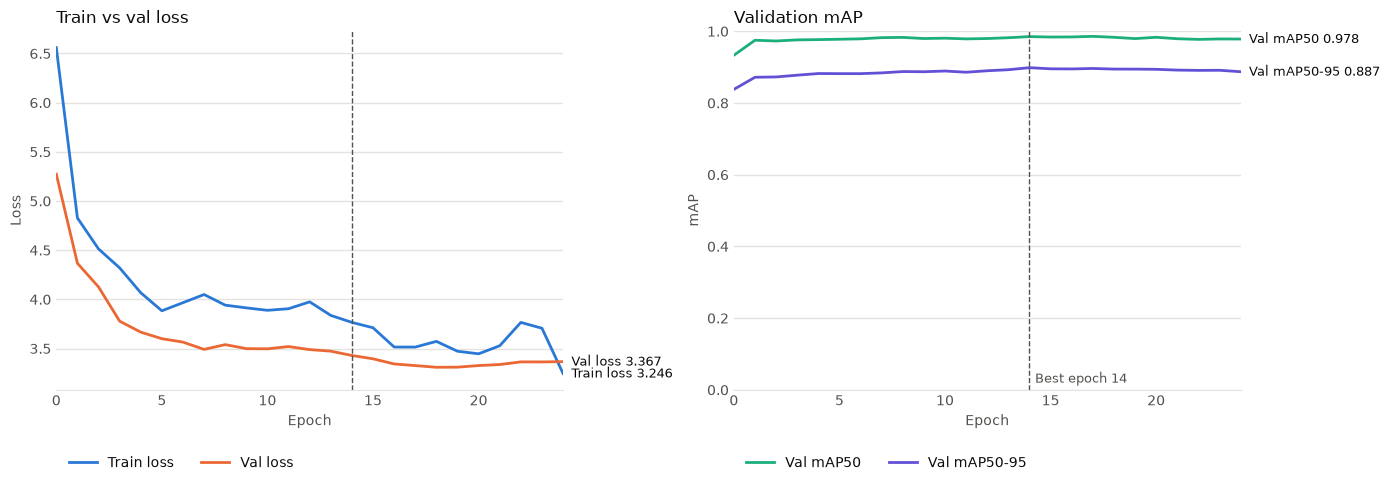

In [ ]:
import matplotlib.pyplot as plt

TEXT, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
SERIES = {
    'train_loss': ('Train loss', '#2a78d6'),
    'val_loss': ('Val loss', '#eb6834'),
    'mAP50': ('Val mAP50', '#1baf7a'),
    'mAP50-95': ('Val mAP50-95', '#6250d6'),
    'train_precision': ('Train precision', '#2a78d6'),
    'precision': ('Val precision', '#eb6834')
}


def plot_panel(ax, keys, title, ylabel, end_labels=True):
    for key in keys:
        if key not in epoch_metrics:
            continue
        series = epoch_metrics[key].dropna()
        label, color = SERIES[key]
        ax.plot(series.index, series.values, color=color, linewidth=2, label=label)
        if not end_labels:
            continue
        # Direct label at the line end so series identity isn't color-alone
        ax.annotate(f'{label} {series.iloc[-1]:.3f}', (series.index[-1], series.iloc[-1]),
                    xytext=(6, 0), textcoords='offset points', va='center', fontsize=9, color=TEXT)
    ax.set_title(title, loc='left', fontsize=12, color=TEXT)
    ax.set_xlabel('Epoch', color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.set_xlim(epoch_metrics.index.min(), epoch_metrics.index.max())
    ax.grid(axis='y', color=GRID, linewidth=1)
    ax.tick_params(colors=MUTED, length=0)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
    ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(0, -0.15), ncol=2, labelcolor=TEXT)


fig, (ax_loss, ax_map, ax_prec) = plt.subplots(1, 3, figsize=(20, 5), sharex=True)
plot_panel(ax_loss, ['train_loss', 'val_loss'], 'Train vs val loss', 'Loss')
plot_panel(ax_map, ['mAP50', 'mAP50-95'], 'Validation mAP', 'mAP')
ax_map.set_ylim(0, 1)
# Train and val precision end within a few points of each other, so the legend identifies them instead of end labels
plot_panel(ax_prec, ['train_precision', 'precision'], 'Train vs val precision', 'Precision', end_labels=False)
ax_prec.set_ylim(top=1)

best_epoch = epoch_metrics['mAP50-95'].idxmax()
for ax in (ax_loss, ax_map, ax_prec):
    ax.axvline(best_epoch, color=MUTED, linewidth=1, linestyle='--')
ax_map.annotate(f'Best epoch {best_epoch}', (best_epoch, 0.02), xytext=(4, 0),
                textcoords='offset points', fontsize=9, color=MUTED)

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'train_val_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
best_path = OUTPUT_DIR / 'checkpoint_best_total.pth'
best_model = from_checkpoint(best_path)

metrics = evaluate(best_model, 'val')

print('Best weights:', best_path)
for name, value in metrics.items():
    print(f'{name}: {value:.4f}')

[2026-10-11 22:43:00] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-11 22:43:00] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-11 22:43:01] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Best weights: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\rfdetr_runs\wildlife_rfdetr_medium\checkpoint_best_total.pth
Precision: 0.9636
Recall: 0.9604
mAP50: 0.9854
mAP50-95: 0.8957
mAP75: 0.9632
Best-F1 confidence: 0.5500


## Save the final trained model

Copies the best checkpoint to `ai-applications/trained_models`.

In [ ]:
final_model_path = TRAINED_MODEL_DIR / 'rfdetr_medium_best.pth'
shutil.copy2(best_path, final_model_path)

print('Final trained model saved to:', final_model_path)

Final trained model saved to: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\trained_models\rfdetr_medium_best.pth


## Evaluate on the test split

In [ ]:
test_metrics = evaluate(best_model, 'test')

results = {
    'Model': MODEL_NAME,
    'Precision': test_metrics['Precision'],
    'Recall': test_metrics['Recall'],
    'mAP50': test_metrics['mAP50'],
    'mAP50-95': test_metrics['mAP50-95'],
    'mAP75': test_metrics['mAP75'],
    'Training time (min)': globals().get('training_time_min'),  # None if the training cell wasn't run this session
    'Best weights': final_model_path.relative_to(PROJECT_ROOT).as_posix()
}

evaluation_df = pd.DataFrame([results])
print(evaluation_df.round(4).to_string(index=False))
print('Best-F1 confidence:', test_metrics['Best-F1 confidence'])

# Same file names / columns as rtdetr_evaluation.csv so the models can be compared directly
evaluation_df.to_csv(RESULTS_DIR / 'rfdetr_evaluation.csv', index=False)
evaluation_df.to_json(RESULTS_DIR / 'rfdetr_evaluation.json', orient='records', indent=2)
print('Saved results to:', RESULTS_DIR / 'rfdetr_evaluation.csv')
print('Saved results to:', RESULTS_DIR / 'rfdetr_evaluation.json')

    Model  Precision  Recall  mAP50  mAP50-95  mAP75  Training time (min)                                          Best weights
RF-DETR-M     0.9833  0.9551 0.9913    0.9033 0.9596              27.6356 ai-applications/trained_models/rfdetr_medium_best.pth
Best-F1 confidence: 0.6


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\zheng\\Documents\\ISY5002-PRS-G14\\ai-applications\\training_results\\rf-detr\\rfdetr_evaluation.csv'

## Inference on a sample test image

Test image: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset\images\test\1 (103).jpg


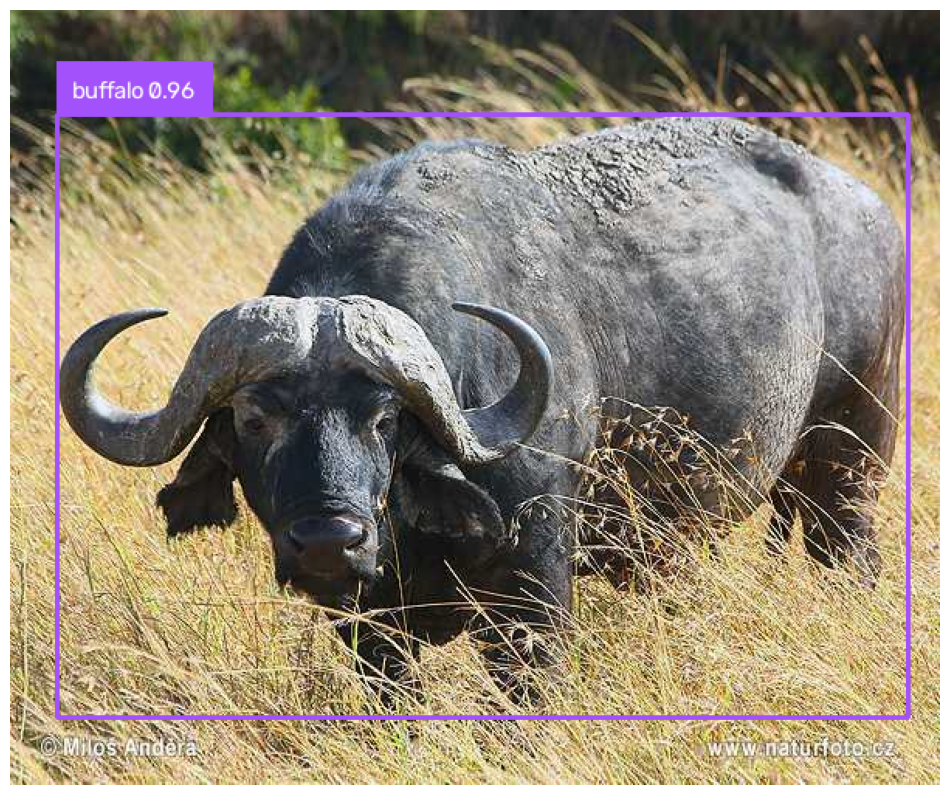

In [ ]:
TEST_IMAGE = next(p for p in test_dir.iterdir() if p.is_file())
print('Test image:', TEST_IMAGE)

prediction = best_model.predict(str(TEST_IMAGE), threshold=0.35)

image = cv2.imread(str(TEST_IMAGE))
labels = [f'{CLASS_NAMES[c]} {p:.2f}' for c, p in zip(prediction.class_id, prediction.confidence)]
annotated = sv.BoxAnnotator().annotate(image.copy(), prediction)
annotated = sv.LabelAnnotator().annotate(annotated, prediction, labels=labels)
cv2.imwrite(str(RESULTS_DIR / 'sample_prediction.jpg'), annotated)
sv.plot_image(annotated)

In [ ]:
for xyxy, class_id, confidence in zip(prediction.xyxy, prediction.class_id, prediction.confidence):
    x1, y1, x2, y2 = xyxy.tolist()
    print({
        'class': CLASS_NAMES[int(class_id)],
        'confidence': round(float(confidence), 4),
        'box': [round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)]
    })

{'class': 'buffalo', 'confidence': 0.9553, 'box': [30.36, 67.57, 579.75, 456.07]}


## Optional: export to ONNX

In [ ]:
onnx_path = best_model.export(output_dir=str(OUTPUT_DIR / 'export'))

final_onnx_path = TRAINED_MODEL_DIR / 'rfdetr_medium_best.onnx'
shutil.copy2(onnx_path, final_onnx_path)
print('ONNX model saved to:', final_onnx_path)

[2026-10-11 22:13:09] [INFO] rf-detr - Exporting model to onnx format


C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\models\backbone\dinov2.py:273: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert x.shape[2] % block_size == 0 and x.shape[3] % block_size == 0, (
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\models\backbone\dinov2_with_windowed_attn.py:436: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if height % divisor != 0 or width % divisor != 0:
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\models\backbone\dinov2_with_windowed_attn.py:327: Tracer

OnnxExporterError: Module onnx is not installed!